# Segmentación no supervisada de clientes de tarjeta de crédito

**Caso:** identificar perfiles de comportamiento de uso y pago.  
**Algoritmos:** K-Means y DBSCAN.  
**Datos:** Credit Card Dataset for Clustering (8.950 registros; 18 columnas).

## Fase 1. Definición del problema

Una entidad financiera desea comprender si sus clientes presentan patrones diferenciados de uso de tarjeta, compras, avances de efectivo y pagos. Se propone agruparlos a partir de sus características de comportamiento.

**Pregunta:** ¿qué perfiles de comportamiento pueden identificarse con K-Means y DBSCAN, y cuál produce una segmentación más útil según las métricas, cobertura e interpretación de los grupos?

**Por qué no supervisado:** el conjunto de datos no contiene una variable objetivo para entrenar una clasificación. Se buscan agrupaciones a partir de similitudes entre observaciones.

**Utilidad esperada:** describir grupos para análisis agregado de productos y servicios.

## Fase 2. Fuente y selección de datos

Se utiliza **Credit Card Dataset for Clustering**, publicado en Kaggle por Arjun Bhasin. Contiene registros de comportamiento de 8.950 titulares de tarjetas durante seis meses y 18 columnas: un identificador y 17 variables numéricas de uso, compras, anticipos y pagos.

El CSV se descarga desde una copia pública del archivo original. Se elimina CUST_ID y se trabaja sin etiquetas.

**Variables incluidas:** saldo (`BALANCE`), frecuencia de actualización del saldo, compras totales y por modalidad, anticipos de efectivo, frecuencias de compra y anticipo, número de transacciones, límite de crédito, pagos realizados, pago mínimo, proporción de pagos completos y antigüedad de la tarjeta (`TENURE`). `CUST_ID` se usa únicamente para identificar el registro y se excluye del análisis.

In [ ]:
import io, json, time, zipfile, warnings, requests, joblib
from IPython.display import display
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
OUT_DIR = Path('/content/resultados_ML_Segmentacion_Clientes')
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True

## Carga y validación del dataset

In [ ]:
DATA_URL = 'https://raw.githubusercontent.com/hereiskky/credit/main/CC%20GENERAL.csv'
response = requests.get(DATA_URL, timeout=90)
response.raise_for_status()
df = pd.read_csv(io.BytesIO(response.content))
df.columns = [str(c).strip().upper() for c in df.columns]

expected = [
    'CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
    'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
    'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
    'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
    'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE'
]
missing_columns = sorted(set(expected) - set(df.columns))
if missing_columns:
    raise ValueError(f'Faltan columnas del dataset: {missing_columns}')

assert len(df) >= 1000, 'El dataset no cumple el mínimo de 1.000 registros.'
assert len(df.columns) >= 5, 'El dataset no cumple el mínimo de cuatro variables y un identificador.'

print(f'Registros: {len(df):,}')
print(f'Columnas: {len(df.columns)}')
print(f'Variables numéricas (sin identificador): {len(df.select_dtypes(include=np.number).columns)}')
display(df.head())

Registros: 8,950
Columnas: 18
Variables numéricas (sin identificador): 17


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## Fase 3. Análisis exploratorio (EDA)

In [ ]:
eda = {
    'registros_iniciales': int(df.shape[0]),
    'columnas_iniciales': int(df.shape[1]),
    'duplicados_exactos': int(df.duplicated().sum()),
    'faltantes_totales': int(df.isna().sum().sum()),
    'variables_numericas': int(len(df.select_dtypes(include=np.number).columns))
}
missing_table = df.isna().sum().rename('faltantes').to_frame()
missing_table['porcentaje'] = (missing_table['faltantes'] / len(df) * 100).round(2)
display(pd.DataFrame([eda]))
display(missing_table[missing_table['faltantes'] > 0].sort_values('faltantes', ascending=False))
display(df.describe().T.round(2))

# Detección exploratoria de valores atípicos mediante el criterio IQR.
eda_num = df.drop(columns=['CUST_ID'], errors='ignore').select_dtypes(include=np.number)
q1 = eda_num.quantile(0.25)
q3 = eda_num.quantile(0.75)
iqr = q3 - q1
outlier_mask = (eda_num.lt(q1 - 1.5 * iqr)) | (eda_num.gt(q3 + 1.5 * iqr))
outlier_table = pd.DataFrame({'outliers_iqr': outlier_mask.sum(), 'porcentaje': (outlier_mask.mean() * 100).round(2)})
display(outlier_table.sort_values('outliers_iqr', ascending=False))


,registros_iniciales,columnas_iniciales,duplicados_exactos,faltantes_totales,variables_numericas
0,8950,18,0,314,17


,faltantes,porcentaje
MINIMUM_PAYMENTS,313,3.50
CREDIT_LIMIT,1,0.01


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


,outliers_iqr,porcentaje
BALANCE_FREQUENCY,1493,16.68
PRC_FULL_PAYMENT,1474,16.47
TENURE,1366,15.26
CASH_ADVANCE,1030,11.51
ONEOFF_PURCHASES,1013,11.32
INSTALLMENTS_PURCHASES,867,9.69
MINIMUM_PAYMENTS,841,9.40
PAYMENTS,808,9.03
PURCHASES,808,9.03
CASH_ADVANCE_TRX,804,8.98


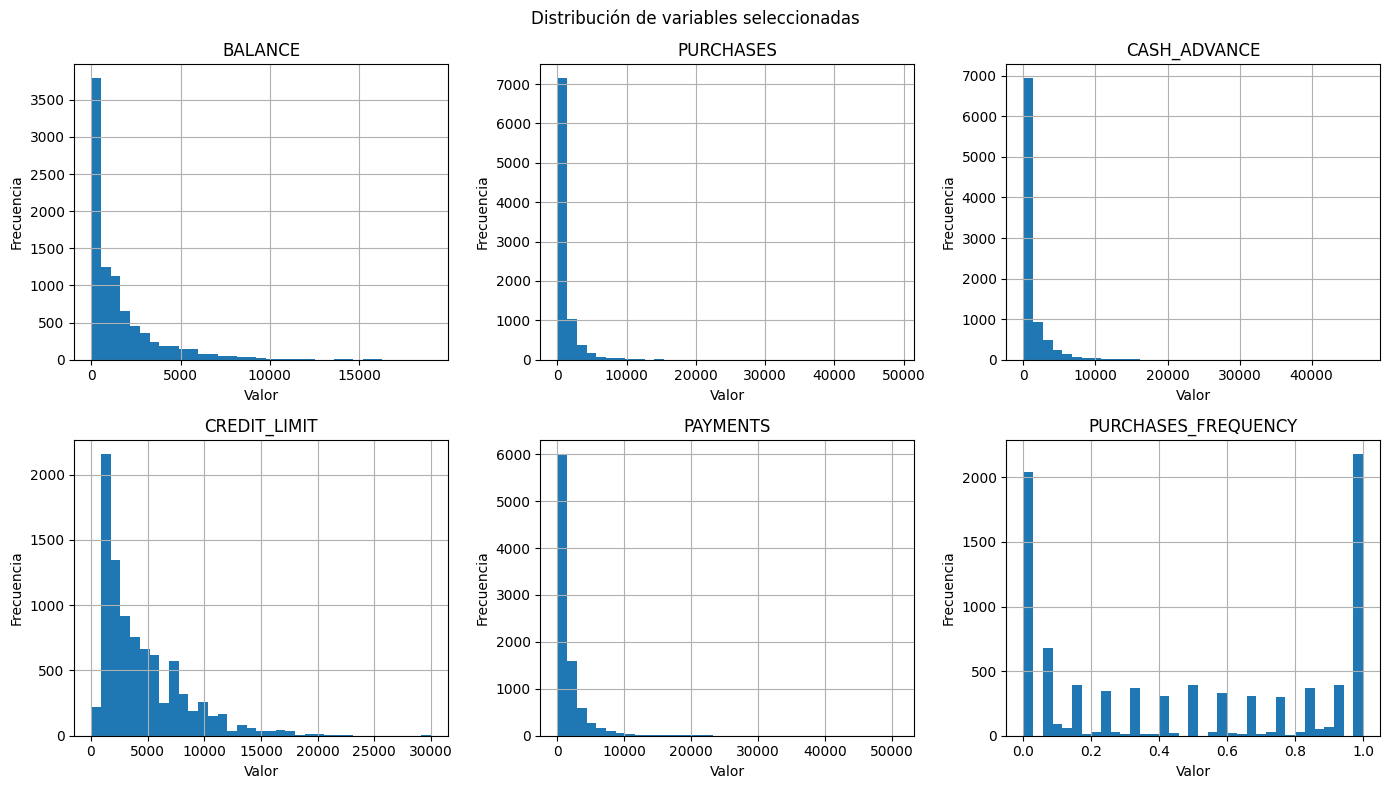

In [ ]:
# Distribuciones de variables principales.
cols_hist = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'PURCHASES_FREQUENCY']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, cols_hist):
    ax.hist(df[col].dropna(), bins=35)
    ax.set_title(col)
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
plt.suptitle('Distribución de variables seleccionadas')
plt.tight_layout()
plt.savefig(OUT_DIR / 'eda_distribuciones.png', dpi=160, bbox_inches='tight')
plt.show()

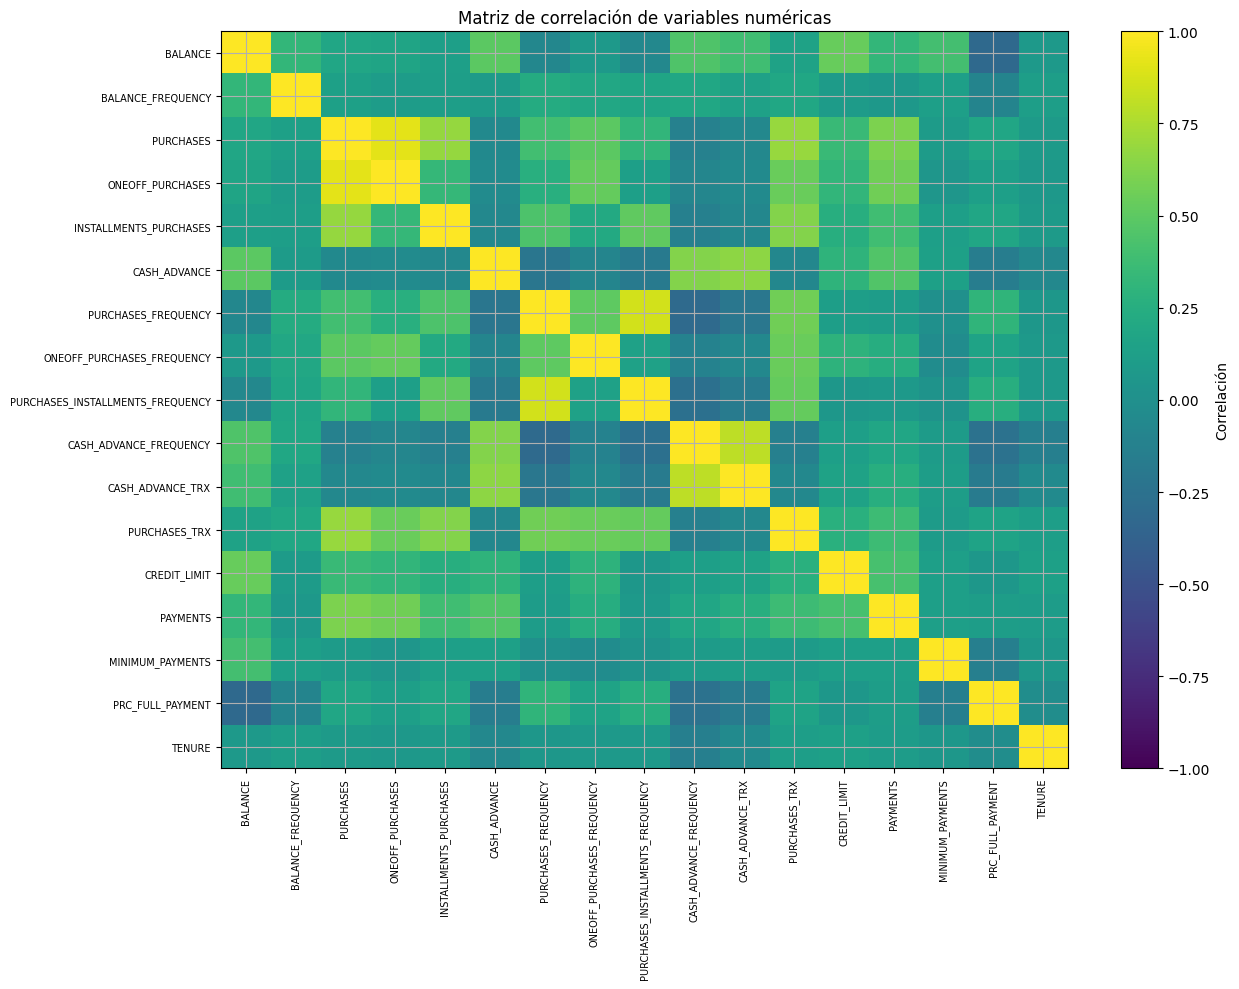

In [ ]:
# Correlaciones de variables numéricas.
eda_numeric = df.drop(columns=['CUST_ID'], errors='ignore').select_dtypes(include=np.number)
plt.figure(figsize=(13, 10))
plt.imshow(eda_numeric.corr(), aspect='auto', vmin=-1, vmax=1)
plt.colorbar(label='Correlación')
plt.xticks(range(len(eda_numeric.columns)), eda_numeric.columns, rotation=90, fontsize=7)
plt.yticks(range(len(eda_numeric.columns)), eda_numeric.columns, fontsize=7)
plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.savefig(OUT_DIR / 'eda_correlaciones.png', dpi=160, bbox_inches='tight')
plt.show()

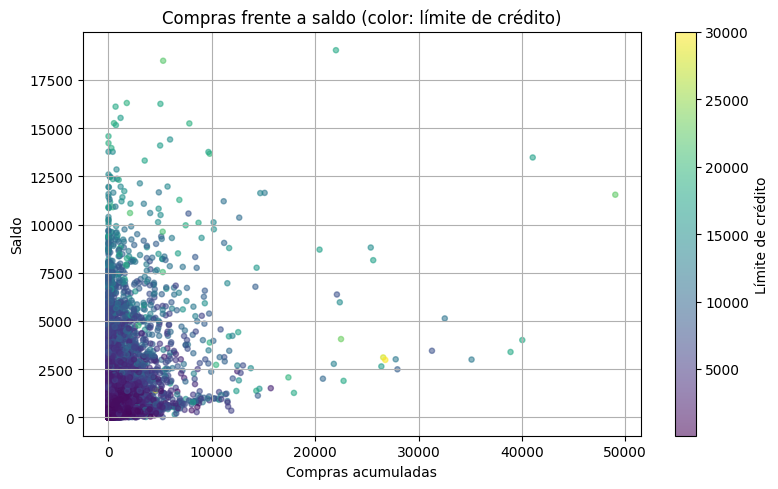

In [ ]:
# Relación entre compras, saldo y límite de crédito.
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(df['PURCHASES'], df['BALANCE'], c=df['CREDIT_LIMIT'], s=14, alpha=0.55)
ax.set_xlabel('Compras acumuladas')
ax.set_ylabel('Saldo')
ax.set_title('Compras frente a saldo (color: límite de crédito)')
fig.colorbar(sc, ax=ax, label='Límite de crédito')
plt.tight_layout()
plt.savefig(OUT_DIR / 'eda_compras_saldo.png', dpi=160, bbox_inches='tight')
plt.show()

## Fase 4. Preprocesamiento

Se seleccionan nueve variables representativas de saldo, compras, anticipos, frecuencia, límite, pagos y antigüedad. Se elimina el identificador, se retiran duplicados exactos, se imputan faltantes con la mediana, se limitan extremos en percentiles 1 y 99, se aplica log1p a variables monetarias y se estandarizan los datos. K-Means y DBSCAN reciben exactamente la misma matriz.

In [ ]:
# El identificador no describe el comportamiento y no entra al modelo.
df_clean = df.drop_duplicates().reset_index(drop=True)
customer_ids = df_clean['CUST_ID'].astype(str).copy()
selected_features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
                    'CASH_ADVANCE_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS',
                    'PRC_FULL_PAYMENT', 'TENURE']
X_raw = df_clean[selected_features].apply(pd.to_numeric, errors='coerce')

# Imputación por mediana.
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=X_raw.columns, index=X_raw.index)

# Recorte de extremos para disminuir el efecto de valores extraordinarios.
lower = X_imputed.quantile(0.01)
upper = X_imputed.quantile(0.99)
X_clipped = X_imputed.clip(lower=lower, upper=upper, axis=1)

# Transformación logarítmica de variables monetarias y conteos no negativos.
log_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']
X_transformed = X_clipped.copy()
for col in log_cols:
    X_transformed[col] = np.log1p(X_transformed[col].clip(lower=0))

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_transformed), columns=X_transformed.columns)

print('Matriz final:', X_scaled.shape)
print('Faltantes después del preprocesamiento:', int(X_scaled.isna().sum().sum()))
display(X_scaled.head())

Matriz final: (8950, 9)
Faltantes después del preprocesamiento: 0


,BALANCE,PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.207587,-0.112263,-0.931270,-0.806490,-0.685371,-1.463907,-0.826302,-0.525551,0.36068
1,0.952090,-1.682446,1.532002,-1.221758,0.593147,0.934568,1.073539,0.234227,0.36068
2,0.827846,0.603757,-0.931270,1.269843,-0.685371,1.019633,-0.117265,-0.525551,0.36068
3,0.626991,0.831088,0.566116,-1.014125,-0.259200,1.019633,-4.182050,-0.525551,0.36068
4,0.272689,-0.708678,-0.931270,-1.014125,-0.685371,-1.239289,-0.062647,-0.525551,0.36068


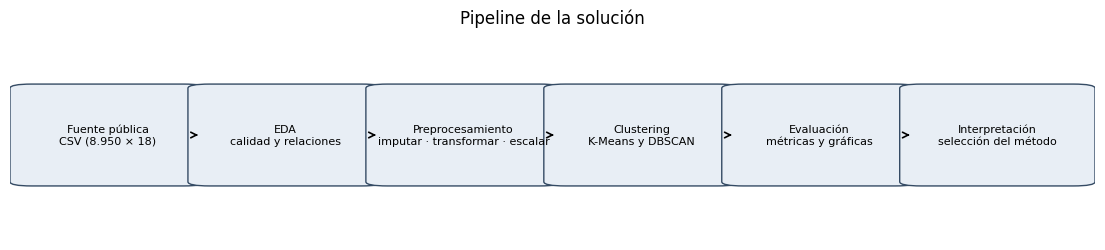

In [ ]:
# Diagrama resumido del pipeline realizado.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(14, 2.7))
ax.axis('off')
steps = ['Fuente pública\nCSV (8.950 × 18)', 'EDA\ncalidad y relaciones', 'Preprocesamiento\nimputar · transformar · escalar', 'Clustering\nK-Means y DBSCAN', 'Evaluación\nmétricas y gráficas', 'Interpretación\nselección del método']
xs = np.linspace(0.02, 0.84, len(steps))
for i, (x, label) in enumerate(zip(xs, steps)):
    box = FancyBboxPatch((x, 0.28), 0.14, 0.45, boxstyle='round,pad=0.02', facecolor='#e8eef5', edgecolor='#354b64')
    ax.add_patch(box)
    ax.text(x + 0.07, 0.505, label, ha='center', va='center', fontsize=8)
    if i < len(steps)-1:
        ax.annotate('', xy=(xs[i+1]-0.008, 0.505), xytext=(x+0.148, 0.505), arrowprops=dict(arrowstyle='->', lw=1.2))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.title('Pipeline de la solución')
plt.savefig(OUT_DIR / 'pipeline_diagrama.png', dpi=160, bbox_inches='tight')
plt.show()

## Fase 5. Implementación de los algoritmos

| Algoritmo | Característica principal | Parámetros importantes |
|---|---|---|
| K-Means | Agrupa por distancia a centroides y requiere definir el número de grupos. | `n_clusters`, `n_init`, `random_state`. |
| DBSCAN | Agrupa regiones densas, admite formas irregulares y marca observaciones aisladas como ruido. | `eps`, `min_samples`. |

Se seleccionan porque representan enfoques complementarios: partición por centroides y agrupación por densidad. Se entrenan sobre la misma matriz estandarizada.

In [ ]:
# K-Means: selección de k mediante Silhouette.
kmeans_rows = []
kmeans_models = {}
for k in range(2, 9):
    start = time.time()
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(X_scaled)
    elapsed = time.time() - start
    score = silhouette_score(X_scaled, labels, sample_size=min(2500, len(X_scaled)), random_state=SEED)
    kmeans_rows.append({'k': k, 'silhouette': score, 'inertia': model.inertia_, 'runtime_seconds': elapsed})
    kmeans_models[k] = model

kmeans_search = pd.DataFrame(kmeans_rows).sort_values('silhouette', ascending=False)
best_k = int(kmeans_search.iloc[0]['k'])
kmeans_model = kmeans_models[best_k]
kmeans_labels = kmeans_model.labels_
print('Mejor k por Silhouette:', best_k)
display(kmeans_search.round(4))

Mejor k por Silhouette: 2


,k,silhouette,inertia,runtime_seconds
0,2,0.2665,59240.7493,0.2171
3,5,0.2612,39373.7722,0.4543
4,6,0.2590,34852.4324,0.4172
2,4,0.2482,44923.1919,0.3671
6,8,0.2458,30073.9856,0.3129
5,7,0.2443,32279.4480,0.3032
1,3,0.2093,51769.9236,0.2751


In [ ]:
# DBSCAN: ajustar eps con una muestra de hasta 4.000 registros para evitar búsquedas costosas.
X_db_tune = X_scaled.sample(n=min(4000, len(X_scaled)), random_state=SEED).reset_index(drop=True)
min_samples_grid = [5, 10]
dbscan_trials = []
for min_s in min_samples_grid:
    nn = NearestNeighbors(n_neighbors=min_s).fit(X_db_tune)
    distances, _ = nn.kneighbors(X_db_tune)
    kth = np.sort(distances[:, -1])
    for q in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45]:
        eps = float(np.quantile(kth, q))
        start = time.time()
        model = DBSCAN(eps=eps, min_samples=min_s)
        labels = model.fit_predict(X_db_tune)
        elapsed = time.time() - start
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        noise_pct = float((~non_noise).mean() * 100)
        min_size = int(pd.Series(labels[non_noise]).value_counts().min()) if n_clusters else 0
        sil = np.nan
        if n_clusters >= 2 and non_noise.sum() > n_clusters + 1:
            idx = np.flatnonzero(non_noise)
            if len(idx) > 2000:
                idx = np.random.default_rng(SEED).choice(idx, 2000, replace=False)
            try:
                sil = float(silhouette_score(X_db_tune.iloc[idx], labels[idx]))
            except Exception:
                pass
        dbscan_trials.append({
            'eps': eps, 'min_samples': min_s, 'n_clusters': n_clusters,
            'noise_pct': noise_pct, 'min_cluster_size': min_size,
            'silhouette_non_noise': sil, 'tuning_runtime_seconds': elapsed
        })

dbscan_search = pd.DataFrame(dbscan_trials)
min_cluster_size = max(5, int(0.001 * len(X_db_tune)))
valid_db = dbscan_search[
    (dbscan_search['n_clusters'] >= 2) &
    dbscan_search['silhouette_non_noise'].notna() &
    (dbscan_search['noise_pct'] < 90) &
    (dbscan_search['min_cluster_size'] >= min_cluster_size)
]
if len(valid_db):
    best_db_row = valid_db.sort_values(['silhouette_non_noise', 'noise_pct'], ascending=[False, True]).iloc[0]
    dbscan_status = 'Se encontró una configuración con al menos dos clústeres y métricas calculables en la muestra de ajuste.'
else:
    best_db_row = dbscan_search.sort_values(['n_clusters', 'noise_pct'], ascending=[False, True]).iloc[0]
    dbscan_status = 'La búsqueda no encontró una configuración DBSCAN con dos clústeres estables y métricas calculables; el resultado completo se reportará como limitación.'

# Reentrenar la configuración seleccionada con todos los registros.
start = time.time()
dbscan_model = DBSCAN(eps=float(best_db_row['eps']), min_samples=int(best_db_row['min_samples']))
dbscan_labels = dbscan_model.fit_predict(X_scaled)
dbscan_runtime = time.time() - start
full_non_noise = dbscan_labels != -1
full_cluster_sizes = pd.Series(dbscan_labels[full_non_noise]).value_counts()
full_n_clusters = int(full_cluster_sizes.size)
full_noise_pct = float((~full_non_noise).mean() * 100)
full_min_cluster_size = int(full_cluster_sizes.min()) if full_n_clusters else 0
if full_n_clusters >= 2 and full_min_cluster_size >= 5 and full_noise_pct < 90:
    dbscan_status = f'DBSCAN identificó {full_n_clusters} clústeres con {full_noise_pct:.1f}% de ruido en el conjunto completo.'
elif full_n_clusters >= 2:
    dbscan_status = f'DBSCAN identificó {full_n_clusters} clústeres, pero hay grupos pequeños o una proporción de ruido que debe considerarse.'
else:
    dbscan_status = 'DBSCAN no identificó más de un clúster en el conjunto completo; K-Means se mantiene como alternativa para comparación.'
print('Configuración DBSCAN seleccionada:', best_db_row.to_dict())
print(dbscan_status)
print('Clústeres finales:', full_n_clusters, '| Ruido:', round(full_noise_pct, 2), '% | Menor clúster:', full_min_cluster_size)
print('Tiempo de ajuste final sobre todos los registros:', round(dbscan_runtime, 3), 'segundos')
display(dbscan_search.round(4))

Configuración DBSCAN seleccionada: {'eps': 0.5639787596064464, 'min_samples': 10.0, 'n_clusters': 12.0, 'noise_pct': 68.325, 'min_cluster_size': 5.0, 'silhouette_non_noise': 0.19244972236512095, 'tuning_runtime_seconds': 0.1853480339050293}
DBSCAN identificó 19 clústeres, pero hay grupos pequeños o una proporción de ruido que debe considerarse.
Clústeres finales: 19 | Ruido: 49.96 % | Menor clúster: 3
Tiempo de ajuste final sobre todos los registros: 0.615 segundos


,eps,min_samples,n_clusters,noise_pct,min_cluster_size,silhouette_non_noise,tuning_runtime_seconds
0,0.4470,5,27,71.725,4,-0.1001,0.1586
1,0.4857,5,36,64.700,3,-0.0747,0.2063
2,0.5174,5,33,58.750,3,-0.1788,0.2017
3,0.5529,5,33,53.400,2,-0.1964,0.2109
4,0.5826,5,30,47.350,3,-0.1700,0.2108
5,0.6134,5,26,42.950,4,-0.1882,0.2285
6,0.5640,10,12,68.325,5,0.1924,0.1853
7,0.6080,10,12,61.100,8,0.1063,0.2290
8,0.6466,10,12,53.750,8,-0.0124,0.2464
9,0.6771,10,10,48.825,9,0.0478,0.2349


## Fase 6. Evaluación y visualizaciones

Se calculan Silhouette, Davies-Bouldin y Calinski-Harabasz. En DBSCAN, las métricas internas se calculan sobre los registros asignados a clústeres y se reporta por separado el porcentaje de ruido.

In [ ]:
def clustering_metrics(X, labels, runtime):
    labels = np.asarray(labels)
    non_noise = labels != -1
    assigned = labels[non_noise]
    X_eval = X.loc[non_noise] if isinstance(X, pd.DataFrame) else X[non_noise]
    n_clusters = len(set(assigned))
    out = {
        'n_clusters': int(n_clusters),
        'noise_pct': float((~non_noise).mean() * 100),
        'coverage_pct': float(non_noise.mean() * 100),
        'runtime_seconds': float(runtime),
        'silhouette': np.nan,
        'davies_bouldin': np.nan,
        'calinski_harabasz': np.nan
    }
    if n_clusters >= 2 and len(assigned) > n_clusters:
        sample_idx = np.arange(len(assigned))
        if len(sample_idx) > 2500:
            sample_idx = np.random.default_rng(SEED).choice(sample_idx, 2500, replace=False)
        X_sample = X_eval.iloc[sample_idx] if isinstance(X_eval, pd.DataFrame) else X_eval[sample_idx]
        labels_sample = assigned[sample_idx]
        if len(np.unique(labels_sample)) >= 2:
            out['silhouette'] = float(silhouette_score(X_sample, labels_sample))
            out['davies_bouldin'] = float(davies_bouldin_score(X_eval, assigned))
            out['calinski_harabasz'] = float(calinski_harabasz_score(X_eval, assigned))
    return out

kmeans_time = float(kmeans_search.loc[kmeans_search['k'] == best_k, 'runtime_seconds'].iloc[0])
dbscan_time = float(dbscan_runtime)
metrics_k = clustering_metrics(X_scaled, kmeans_labels, kmeans_time)
metrics_d = clustering_metrics(X_scaled, dbscan_labels, dbscan_time)
metrics_table = pd.DataFrame([
    {'algorithm': 'K-Means', 'parameters': f'k={best_k}', **metrics_k},
    {'algorithm': 'DBSCAN', 'parameters': f"eps={dbscan_model.eps:.4f}; min_samples={dbscan_model.min_samples}", **metrics_d}
])
display(metrics_table.round(4))

,algorithm,parameters,n_clusters,noise_pct,coverage_pct,runtime_seconds,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,k=2,2,0.0000,100.0000,0.2171,0.2645,1.5468,3218.6523
1,DBSCAN,eps=0.5640; min_samples=10,19,49.9553,50.0447,0.6153,-0.1248,1.2047,282.6323


In [ ]:
# Tamaños de clúster y ruido.
size_rows = []
for name, labels in [('K-Means', kmeans_labels), ('DBSCAN', dbscan_labels)]:
    counts = pd.Series(labels).value_counts().sort_index()
    for cluster, count in counts.items():
        size_rows.append({'algorithm': name, 'cluster': int(cluster), 'records': int(count),
                          'percentage': float(count / len(labels) * 100),
                          'is_noise': bool(cluster == -1)})
cluster_sizes = pd.DataFrame(size_rows)
display(cluster_sizes)

,algorithm,cluster,records,percentage,is_noise
0,K-Means,0,5118,57.184358,False
1,K-Means,1,3832,42.815642,False
2,DBSCAN,-1,4471,49.955307,True
3,DBSCAN,0,49,0.547486,False
4,DBSCAN,1,2687,30.022346,False
5,DBSCAN,2,1211,13.530726,False
6,DBSCAN,3,48,0.536313,False
7,DBSCAN,4,10,0.111732,False
8,DBSCAN,5,215,2.402235,False
9,DBSCAN,6,83,0.927374,False


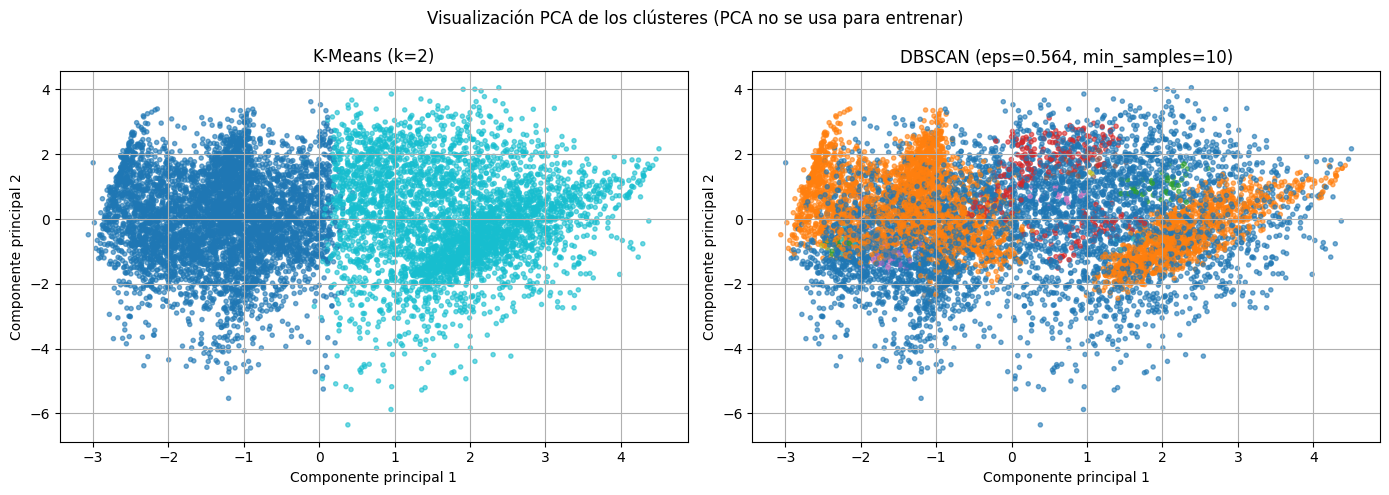

Varianza explicada por PCA: [0.3363 0.2267] Total: 0.563


In [ ]:
# Proyección PCA en dos dimensiones, solo para visualizar los grupos.
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, s=9, alpha=0.6, cmap='tab10')
axes[0].set_title(f'K-Means (k={best_k})')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, s=9, alpha=0.6, cmap='tab10')
axes[1].set_title(f'DBSCAN (eps={dbscan_model.eps:.3f}, min_samples={dbscan_model.min_samples})')
for ax in axes:
    ax.set_xlabel('Componente principal 1')
    ax.set_ylabel('Componente principal 2')
plt.suptitle('Visualización PCA de los clústeres (PCA no se usa para entrenar)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'comparacion_clusters_pca.png', dpi=160, bbox_inches='tight')
plt.show()
print('Varianza explicada por PCA:', pca.explained_variance_ratio_.round(4), 'Total:', round(float(pca.explained_variance_ratio_.sum()), 4))

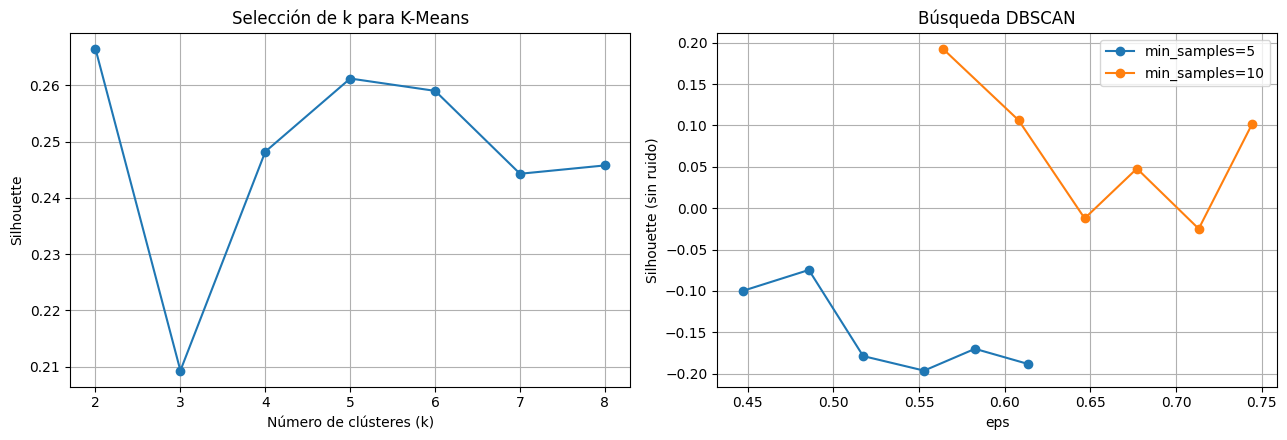

In [ ]:
# Métricas y curva de selección de parámetros.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(kmeans_search.sort_values('k')['k'], kmeans_search.sort_values('k')['silhouette'], marker='o')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Silhouette')
axes[0].set_title('Selección de k para K-Means')
valid_plot = dbscan_search.dropna(subset=['silhouette_non_noise'])
for min_s, group in valid_plot.groupby('min_samples'):
    axes[1].plot(group['eps'], group['silhouette_non_noise'], marker='o', label=f'min_samples={min_s}')
axes[1].set_xlabel('eps')
axes[1].set_ylabel('Silhouette (sin ruido)')
axes[1].set_title('Búsqueda DBSCAN')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'seleccion_parametros.png', dpi=160, bbox_inches='tight')
plt.show()

## Fase 7. Interpretación y selección

Se comparan calidad interna, cantidad de grupos, tamaño de cada grupo, ruido (DBSCAN) y facilidad de interpretación. Las métricas no representan exactitud frente a una etiqueta verdadera porque el problema no tiene etiquetas

In [ ]:
# Perfiles por algoritmo: mediana de las variables originales de comportamiento.
source_features = X_imputed.copy()
source_features.insert(0, 'CUST_ID', customer_ids.values)
source_features['KMEANS_CLUSTER'] = kmeans_labels
source_features['DBSCAN_CLUSTER'] = dbscan_labels

profile_k = source_features.groupby('KMEANS_CLUSTER').median(numeric_only=True)
profile_d = source_features.groupby('DBSCAN_CLUSTER').median(numeric_only=True)
print('Perfil mediano por clúster - K-Means')
display(profile_k.round(2))
print('Perfil mediano por clúster - DBSCAN (-1 representa ruido)')
display(profile_d.round(2))

Perfil mediano por clúster - K-Means


,BALANCE,PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE,DBSCAN_CLUSTER
KMEANS_CLUSTER,,,,,,,,,,
0,239.01,640.74,0.00,0.8,0.00,3000.0,745.31,0.0,12.0,1.0
1,1734.10,0.00,1405.73,0.0,0.25,3000.0,1030.11,0.0,12.0,-1.0


Perfil mediano por clúster - DBSCAN (-1 representa ruido)


,BALANCE,PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE,KMEANS_CLUSTER
DBSCAN_CLUSTER,,,,,,,,,,
-1,621.39,315.20,265.33,0.42,0.08,3000.0,819.88,0.00,12.0,1.0
0,26.79,99.00,0.00,0.17,0.00,1200.0,165.77,0.00,12.0,0.0
1,528.11,872.94,0.00,0.92,0.00,4000.0,907.60,0.00,12.0,0.0
2,1783.62,0.00,1124.28,0.00,0.25,3000.0,809.81,0.00,12.0,1.0
3,4349.67,154.94,2733.87,0.08,0.25,7000.0,1263.47,0.00,12.0,1.0
4,35.48,367.36,0.00,0.50,0.00,1350.0,772.90,1.00,12.0,0.0
5,3472.81,1483.12,1029.56,1.00,0.17,6000.0,1537.65,0.00,12.0,1.0
6,1586.13,129.05,234.64,0.08,0.17,1950.0,530.07,0.00,12.0,1.0
7,57.86,600.00,0.00,0.33,0.00,6000.0,1431.00,1.00,12.0,0.0


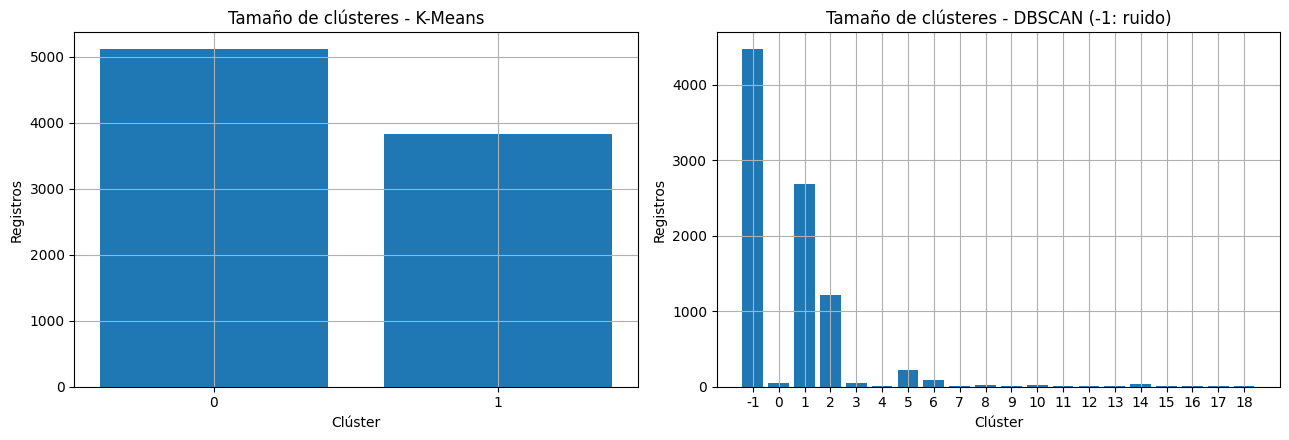

In [ ]:
# Gráfico de tamaños de los segmentos.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
counts_k = pd.Series(kmeans_labels).value_counts().sort_index()
axes[0].bar(counts_k.index.astype(str), counts_k.values)
axes[0].set_title('Tamaño de clústeres - K-Means')
axes[0].set_xlabel('Clúster'); axes[0].set_ylabel('Registros')
counts_d = pd.Series(dbscan_labels).value_counts().sort_index()
axes[1].bar(counts_d.index.astype(str), counts_d.values)
axes[1].set_title('Tamaño de clústeres - DBSCAN (-1: ruido)')
axes[1].set_xlabel('Clúster'); axes[1].set_ylabel('Registros')
plt.tight_layout()
plt.savefig(OUT_DIR / 'tamano_clusters.png', dpi=160, bbox_inches='tight')
plt.show()